# Segmentasi Schizont Malaria pada MP-IDB dengan Image Processing Klasik

Notebook ini mengimplementasikan rancangan pada `docs/presentasi.pdf` dengan detail pendukung dari `docs/draft-docs.md`.

**Ruang lingkup saat ini**
- Spesies: *Plasmodium falciparum* dan *Plasmodium vivax*.
- Stadium: **schizont tunggal** (single-stage schizont).
- Total 8 citra: 4 train + 4 test; 2 train + 2 test per spesies.
- Resolusi penuh 2592 x 1944, **tanpa resizing**.
- Preprocessing minimal untuk Eksperimen A: pemilihan kanal warna + median 3x3.
- GLCM block-wise 32x32, stride 32 sebagai preprocessing pada Eksperimen B.
- If-else pixel-level dan if-else object-level (object-level hanya diterapkan pada output pixel-if-else).

**Eksperimen**
- **A**: Otsu multilevel 3 kelas, adaptive thresholding, k-means k=3, dan pixel-level if-else dengan preprocessing minimal yang sama.
- **B**: variasi preprocessing pada pixel-if-else: CLAHE, background correction, block GLCM, LBP/local stats, dan kombinasi.
- **C**: post-processing pada pixel-if-else: raw, morphology, object-level if-else, object-level + texture.

**Catatan penting**
- Tuning hanya dilakukan pada 4 citra train. 4 citra test tidak dipakai untuk memilih threshold.
- Dengan 8 citra dan 1-2 objek per citra, hasil bersifat **eksploratif**, bukan klaim generalisasi.
- Dataset berupa JPG sehingga artefak kompresi memengaruhi GLCM/LBP.
- Stage pada anotasi bersifat image-level; seleksi dilakukan pada citra yang hanya memiliki tag `schizont`.

In [1]:
from pathlib import Path
import json, base64, zlib, io, random, time, warnings

import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi

from skimage.filters import threshold_multiotsu
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.measure import label, regionprops
from skimage.morphology import remove_small_objects

warnings.filterwarnings('ignore')
%matplotlib inline
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

ROOT = Path('/home/opencode/workspace/mp-idb-DatasetNinja')
IMG_DIR = ROOT / 'ds' / 'img'
ANN_DIR = ROOT / 'ds' / 'ann'

CACHE_DIR = Path('/home/opencode/workspace/cache')
RESULTS_DIR = Path('/home/opencode/workspace/results')
CACHE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
BLOCK = 32
LEVELS = 16
GLCM_DISTANCES = (1, 2)
GLCM_ANGLES = (0, np.pi / 4, np.pi / 2, 3 * np.pi / 4)
CACHE_VERSION = 'v1'

print('Dataset root :', ROOT)
print('Image dir    :', IMG_DIR)
print('Annotation   :', ANN_DIR)
print('Cache dir    :', CACHE_DIR)
print('Results dir  :', RESULTS_DIR)
print('OpenCV       :', cv2.__version__)

Dataset root : /home/opencode/workspace/mp-idb-DatasetNinja
Image dir    : /home/opencode/workspace/mp-idb-DatasetNinja/ds/img
Annotation   : /home/opencode/workspace/mp-idb-DatasetNinja/ds/ann
Cache dir    : /home/opencode/workspace/cache
Results dir  : /home/opencode/workspace/results
OpenCV       : 5.0.0


## 2. Inventaris dataset dan pemilihan 8 citra

Anotasi MP-IDB menyimpan mask sebagai bitmap 1-bit yang dikompresi `zlib` lalu `base64`.
Setiap objek punya `origin` `(x, y)`; mask ditempatkan pada koordinat tersebut.

Kriteria seleksi:
1. Citra hanya memiliki tag stadium `schizont` (single-stage).
2. Spesies falciparum atau vivax.
3. Untuk tiap spesies, citra diurutkan berdasarkan total luas GT, lalu dibagi low/high.
4. Dari tiap kelompok dipilih 1 train + 1 test secara deterministik dengan seed 42.
   Dengan demikian train dan test masing-masing memiliki satu objek kecil dan satu objek besar.

In [2]:
def decode_annotation(ann_path):
    """Decode all object bitmaps into a binary GT mask and an instance-label map."""
    d = json.loads(Path(ann_path).read_text())
    h = int(d['size']['height'])
    w = int(d['size']['width'])
    gt = np.zeros((h, w), dtype=np.uint8)
    gt_labels = np.zeros((h, w), dtype=np.int32)
    objects = []

    for i, obj in enumerate(d['objects'], start=1):
        png = zlib.decompress(base64.b64decode(obj['bitmap']['data']))
        m = np.array(Image.open(io.BytesIO(png)).convert('1'), dtype=np.uint8) > 0
        x, y = map(int, obj['bitmap']['origin'])
        mh, mw = m.shape
        mh = min(mh, h - y)
        mw = min(mw, w - x)
        if mh <= 0 or mw <= 0:
            continue
        m = m[:mh, :mw]
        gt[y:y + mh, x:x + mw] |= m.astype(np.uint8)
        sub = gt_labels[y:y + mh, x:x + mw]
        sub[m] = i
        objects.append({
            'label': i,
            'area': int(m.sum()),
            'bbox': (y, x, y + mh, x + mw),
            'classTitle': obj.get('classTitle', ''),
        })
    return d, gt, gt_labels, objects


def build_inventory():
    rows = []
    for ann_path in sorted(ANN_DIR.glob('*.json')):
        d = json.loads(ann_path.read_text())
        stages = [
            str(t.get('name', '')).lower().replace(' stage', '').strip()
            for t in d.get('tags', [])
            if 'stage' in str(t.get('name', '')).lower()
        ]
        if stages != ['schizont']:
            continue
        classes = {str(o.get('classTitle', '')).lower() for o in d.get('objects', [])}
        if len(classes) != 1:
            continue
        species = next(iter(classes))
        if species not in ('falciparum', 'vivax'):
            continue
        _, gt, _, objects = decode_annotation(ann_path)
        image_id = ann_path.name[:-5]  # remove .json
        rows.append({
            'image_id': image_id,
            'species': species,
            'n_objects': len(objects),
            'areas': [o['area'] for o in objects],
            'total_area': int(sum(o['area'] for o in objects)),
            'image_path': str(IMG_DIR / image_id),
            'ann_path': str(ann_path),
        })
    return pd.DataFrame(rows)


def select_splits(df, seed=SEED):
    rng = random.Random(seed)
    selected = []
    for species in ('falciparum', 'vivax'):
        sub = (df[df['species'] == species]
               .sort_values(['total_area', 'image_id'])
               .reset_index(drop=True))
        mid = len(sub) // 2
        low = list(sub.iloc[:mid].index)
        high = list(sub.iloc[mid:].index)

        low_pick = rng.sample(low, 2)
        high_pick = rng.sample(high, 2)

        # 1 low + 1 high untuk train, 1 low + 1 high untuk test
        for idx, split in (
            (low_pick[0], 'train'), (high_pick[0], 'train'),
            (low_pick[1], 'test'), (high_pick[1], 'test'),
        ):
            row = sub.loc[idx].to_dict()
            row['split'] = split
            selected.append(row)

    out = pd.DataFrame(selected)
    out['species'] = pd.Categorical(out['species'], categories=['falciparum', 'vivax'], ordered=True)
    out['split'] = pd.Categorical(out['split'], categories=['train', 'test'], ordered=True)
    return out.sort_values(['species', 'split', 'total_area']).reset_index(drop=True)


inventory = build_inventory()
selected = select_splits(inventory, seed=SEED)

print('Kandidat single-stage schizont:')
print(inventory.groupby('species').agg(n_images=('image_id', 'count'),
                                        n_objects=('n_objects', 'sum'),
                                        total_area=('total_area', 'sum')))
print('\n8 citra terpilih:')
display(selected[['image_id', 'species', 'split', 'n_objects', 'areas', 'total_area']])

Kandidat single-stage schizont:
            n_images  n_objects  total_area
species                                    
falciparum        11         11      102230
vivax              9         10      197129

8 citra terpilih:


,image_id,species,split,n_objects,areas,total_area
0,1305121398-0012-S.jpg,falciparum,train,1,[6575],6575
1,1305121398-0021-S.jpg,falciparum,train,1,[12820],12820
2,1305121398-0010-S.jpg,falciparum,test,1,[8910],8910
3,1305121398-0022-S.jpg,falciparum,test,1,[9940],9940
4,1709041080-0037-S.jpg,vivax,train,1,[15366],15366
5,1703121298-0002-S.jpg,vivax,train,1,[19433],19433
6,1709041080-0038-S.jpg,vivax,test,1,[12772],12772
7,1709041080-0030-S.jpg,vivax,test,1,[19371],19371


## 3. Memuat 8 citra terpilih

Citra dimuat pada resolusi penuh. GT dan instance-label disimpan untuk evaluasi pixel-level dan object-level.
Mask instance penting karena satu citra vivax dapat memiliki dua objek schizont.

In [3]:
records = []
for _, row in selected.iterrows():
    d, gt, gt_labels, objects = decode_annotation(row['ann_path'])
    bgr = cv2.imread(str(row['image_path']), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(row['image_path'])
    records.append({
        'image_id': row['image_id'],
        'species': str(row['species']),
        'split': str(row['split']),
        'bgr': bgr,
        'gt': gt,
        'gt_labels': gt_labels,
        'objects': objects,
        'shape': bgr.shape[:2],
    })

TRAIN = [r for r in records if r['split'] == 'train']
TEST = [r for r in records if r['split'] == 'test']

summary = pd.DataFrame([{
    'image_id': r['image_id'],
    'species': r['species'],
    'split': r['split'],
    'height': r['shape'][0],
    'width': r['shape'][1],
    'n_gt_objects': len(r['objects']),
    'gt_area': int(r['gt'].sum()),
} for r in records])
display(summary)

print('Train:', len(TRAIN), '| Test:', len(TEST))
print('Train IDs:', [r['image_id'] for r in TRAIN])
print('Test IDs :', [r['image_id'] for r in TEST])

,image_id,species,split,height,width,n_gt_objects,gt_area
0,1305121398-0012-S.jpg,falciparum,train,1944,2592,1,6575
1,1305121398-0021-S.jpg,falciparum,train,1944,2592,1,12820
2,1305121398-0010-S.jpg,falciparum,test,1944,2592,1,8910
3,1305121398-0022-S.jpg,falciparum,test,1944,2592,1,9940
4,1709041080-0037-S.jpg,vivax,train,1944,2592,1,15366
5,1703121298-0002-S.jpg,vivax,train,1944,2592,1,19433
6,1709041080-0038-S.jpg,vivax,test,1944,2592,1,12772
7,1709041080-0030-S.jpg,vivax,test,1944,2592,1,19371


Train: 4 | Test: 4
Train IDs: ['1305121398-0012-S.jpg', '1305121398-0021-S.jpg', '1709041080-0037-S.jpg', '1703121298-0002-S.jpg']
Test IDs : ['1305121398-0010-S.jpg', '1305121398-0022-S.jpg', '1709041080-0038-S.jpg', '1709041080-0030-S.jpg']


## 4. Preprocessing dan feature maps

Semua operasi dilakukan pada resolusi penuh.

- **Median 3x3** diterapkan pada kanal Lab dan saturasi.
- **L** = lightness Lab.
- **P** = purple score = `a - b` (kanal `a` tinggi dan `b` rendah menandakan magenta/ungu).
- **S** = saturasi HSV.
- **CLAHE** diterapkan pada L.
- **Background correction** memakai morphological closing pada citra downscale, lalu `L / background * 255`.
- **Block GLCM**: 32x32, stride 32, 16 level, distance 1 dan 2, empat arah.
- **LBP**: `P=8, R=1`, histogram per blok 32x32; entropy dan uniformity.
- **Local stats**: mean/std pada window 31x31.

Feature map disimpan di cache dalam resolusi blok agar tidak memakan disk besar.
Saat dipakai, map di-upsample bilinear ke resolusi penuh dan dinormalisasi per citra.

In [4]:
def percentile_norm(x, lo=1, hi=99):
    x = np.asarray(x, dtype=np.float32)
    p1, p2 = np.percentile(x, [lo, hi])
    if p2 <= p1:
        return np.zeros_like(x, dtype=np.float32)
    return np.clip((x - p1) / (p2 - p1), 0.0, 1.0)


def median3(x):
    return cv2.medianBlur(x, 3)


def apply_clahe(x, clip_limit=2.0, tile=8):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(tile, tile))
    return clahe.apply(x)


def estimate_background(x, down=4, frac=0.08):
    h, w = x.shape
    sw, sh = max(1, w // down), max(1, h // down)
    small = cv2.resize(x, (sw, sh), interpolation=cv2.INTER_AREA)
    k = int(min(sw, sh) * frac)
    k = max(15, k)
    if k % 2 == 0:
        k += 1
    k = min(k, min(sw, sh))
    if k % 2 == 0:
        k -= 1
    k = max(3, k)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    bg = cv2.morphologyEx(small, cv2.MORPH_CLOSE, kernel)
    return cv2.resize(bg, (w, h), interpolation=cv2.INTER_LINEAR)


def correct_background(x, bg):
    out = x.astype(np.float32) / (bg.astype(np.float32) + 1e-6) * 255.0
    return np.clip(out, 0, 255).astype(np.uint8)


def local_stats(x, ksize=31):
    xf = x.astype(np.float32)
    mean = cv2.boxFilter(xf, -1, (ksize, ksize))
    mean2 = cv2.boxFilter(xf * xf, -1, (ksize, ksize))
    std = np.sqrt(np.maximum(mean2 - mean * mean, 0.0))
    return mean, std


def upsample_map(m, h, w):
    return cv2.resize(m.astype(np.float32), (w, h), interpolation=cv2.INTER_LINEAR)


def preprocess_variant(rec, variant):
    """Return L, a, b after variant-specific preprocessing."""
    lab = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)
    L, a, b = median3(L), median3(a), median3(b)

    if variant in ('clahe', 'combo'):
        L = apply_clahe(L)
    if variant in ('bg', 'combo'):
        bg = estimate_background(L)
        L = correct_background(L, bg)
    return L, a, b


def block_glcm_maps(L, block=BLOCK, levels=LEVELS):
    """GLCM features per block, returned at block resolution."""
    h, w = L.shape
    gh, gw = h // block, w // block
    q = np.clip((percentile_norm(L) * (levels - 1)).astype(np.uint8), 0, levels - 1)
    keys = ('contrast', 'homogeneity', 'energy', 'correlation')
    out = {f'glcm_{k}': np.zeros((gh, gw), dtype=np.float32) for k in keys}

    for gy in range(gh):
        for gx in range(gw):
            blk = q[gy * block:(gy + 1) * block, gx * block:(gx + 1) * block]
            g = graycomatrix(
                blk,
                distances=list(GLCM_DISTANCES),
                angles=list(GLCM_ANGLES),
                levels=levels,
                symmetric=True,
                normed=True,
            )
            for k in keys:
                out[f'glcm_{k}'][gy, gx] = float(graycoprops(g, k).mean())
    return out


def block_lbp_maps(L, block=BLOCK, P=8, R=1):
    """LBP histogram entropy/uniformity per block, returned at block resolution."""
    h, w = L.shape
    gh, gw = h // block, w // block
    n_bins = P + 2
    lbp = local_binary_pattern(L, P, R, method='uniform').astype(np.uint8)
    ent = np.zeros((gh, gw), dtype=np.float32)
    uni = np.zeros((gh, gw), dtype=np.float32)

    for gy in range(gh):
        for gx in range(gw):
            blk = lbp[gy * block:(gy + 1) * block, gx * block:(gx + 1) * block]
            hist = np.bincount(blk.ravel(), minlength=n_bins).astype(np.float32)
            p = hist / (hist.sum() + 1e-8)
            nz = p[p > 0]
            ent[gy, gx] = -float(np.sum(nz * np.log2(nz)))
            uni[gy, gx] = float(np.sum(p * p))
    return {'lbp_entropy': ent, 'lbp_uniformity': uni}


def cache_path(rec, variant, kind):
    safe = rec['image_id'].replace('.jpg', '').replace('/', '_')
    return CACHE_DIR / f'{CACHE_VERSION}__{safe}__{variant}__{kind}__b{BLOCK}_l{LEVELS}.npz'


def get_texture_block_maps(rec, variant, use_glcm=False, use_lbp=False):
    """Load or compute block-resolution texture maps. Cached on disk."""
    out = {}

    if use_glcm:
        path = cache_path(rec, variant, 'glcm')
        if path.exists():
            data = np.load(path)
            out.update({k: data[k] for k in data.files})
        else:
            L, _, _ = preprocess_variant(rec, variant)
            t0 = time.time()
            maps = block_glcm_maps(L)
            np.savez_compressed(path, **maps)
            print(f"  GLCM {rec['image_id']} [{variant}]: {time.time()-t0:.1f}s")
            out.update(maps)

    if use_lbp:
        path = cache_path(rec, variant, 'lbp')
        if path.exists():
            data = np.load(path)
            out.update({k: data[k] for k in data.files})
        else:
            L, _, _ = preprocess_variant(rec, variant)
            t0 = time.time()
            maps = block_lbp_maps(L)
            np.savez_compressed(path, **maps)
            print(f"  LBP  {rec['image_id']} [{variant}]: {time.time()-t0:.1f}s")
            out.update(maps)

    return out

In [5]:
def feature_bundle(rec, variant='base', use_glcm=False, use_lbp=False):
    L, a, b = preprocess_variant(rec, variant)
    hsv = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2HSV)
    S = median3(hsv[:, :, 1])
    P = a.astype(np.float32) - b.astype(np.float32)

    L_n = percentile_norm(L)
    P_n = percentile_norm(P)
    S_n = percentile_norm(S)
    _, sd = local_stats(L, ksize=31)
    sd_n = percentile_norm(sd)

    feat = {
        'variant': variant,
        'L': L, 'P': P, 'S': S,
        'L_n': L_n, 'P_n': P_n, 'S_n': S_n,
        'sd': sd, 'sd_n': sd_n,
    }

    texture_maps = [sd_n]
    block_maps = get_texture_block_maps(rec, variant, use_glcm=use_glcm, use_lbp=use_lbp)
    for k, v in block_maps.items():
        up = upsample_map(v, *L.shape)
        nk = f'{k}_n'
        feat[nk] = percentile_norm(up)
        # local std + GLCM contrast + LBP entropy dianggap sebagai texture cues
        if ('contrast' in k) or ('entropy' in k):
            texture_maps.append(feat[nk])

    if len(texture_maps) == 1:
        feat['texture_n'] = sd_n.copy()
    else:
        feat['texture_n'] = np.mean(np.stack(texture_maps, axis=0), axis=0).astype(np.float32)
    return feat

## 5. Demo preprocessing pada satu citra train

Panel berikut memperlihatkan pengaruh median, CLAHE, background correction, serta contoh feature map GLCM/LBP.
Semua ditampilkan pada crop di sekitar GT agar struktur parasite terlihat.

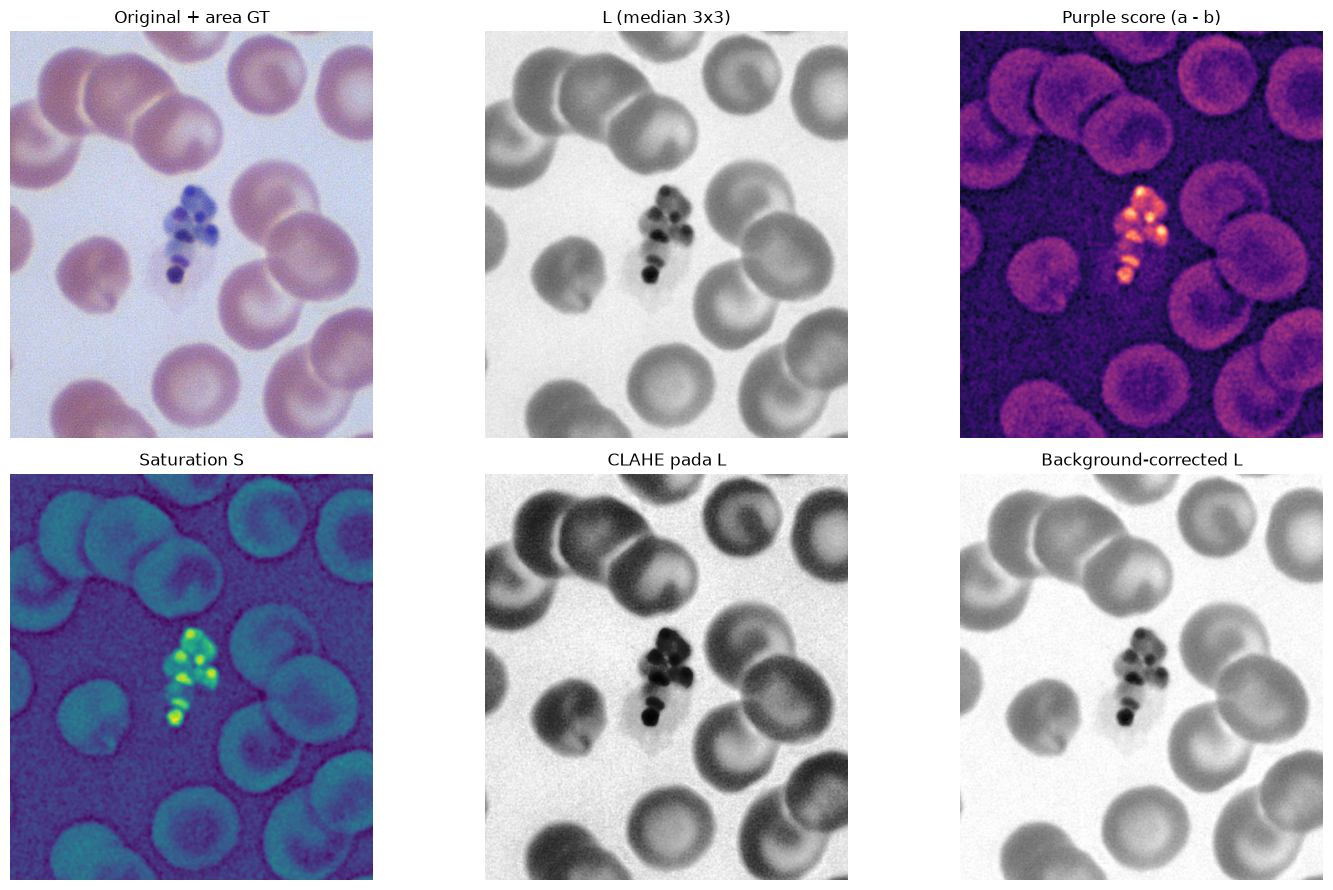

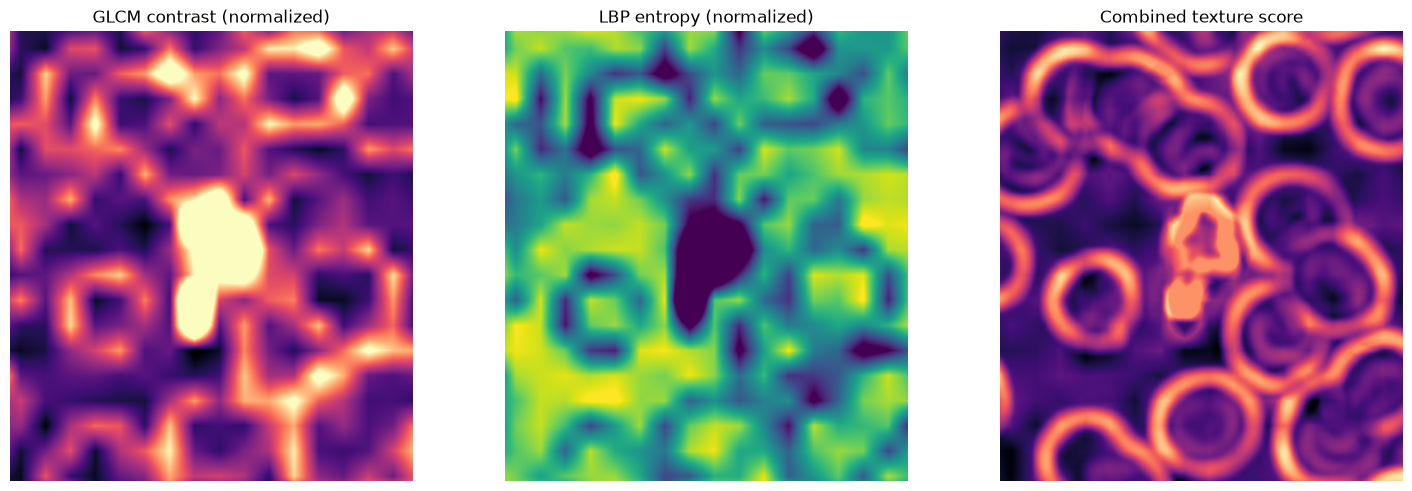

In [6]:
demo = TRAIN[0]
L_base, a_base, b_base = preprocess_variant(demo, 'base')
L_clahe = apply_clahe(L_base)
bg = estimate_background(L_base)
L_bg = correct_background(L_base, bg)
feat_demo = feature_bundle(demo, 'base', use_glcm=True, use_lbp=True)

ys, xs = np.where(demo['gt'] > 0)
pad = 220
y0, y1 = max(0, ys.min() - pad), min(demo['shape'][0], ys.max() + pad)
x0, x1 = max(0, xs.min() - pad), min(demo['shape'][1], xs.max() + pad)

def crop(x):
    return x[y0:y1, x0:x1]

rgb = cv2.cvtColor(crop(demo['bgr']), cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
panels = [
    (rgb, 'Original + area GT', None),
    (crop(L_base), 'L (median 3x3)', 'gray'),
    (crop(feat_demo['P']), 'Purple score (a - b)', 'magma'),
    (crop(feat_demo['S']), 'Saturation S', 'viridis'),
    (crop(L_clahe), 'CLAHE pada L', 'gray'),
    (crop(L_bg), 'Background-corrected L', 'gray'),
]
for ax, (img, title, cmap) in zip(axes.ravel(), panels):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
tex_panels = [
    (crop(feat_demo['glcm_contrast_n']), 'GLCM contrast (normalized)', 'magma'),
    (crop(feat_demo['lbp_entropy_n']), 'LBP entropy (normalized)', 'viridis'),
    (crop(feat_demo['texture_n']), 'Combined texture score', 'magma'),
]
for ax, (img, title, cmap) in zip(axes.ravel(), tex_panels):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Perbandingan kanal warna pada train

Kita mengukur standardized mean difference antara piksel GT dan ring di sekitarnya.
Nilai absolut besar berarti kanal tersebut memisahkan parasite dari latar lokal.
Effect size ini hanya menunjukkan pemisahan lokal; pemilihan final kanal untuk Otsu/adaptive memakai Dice pada train (sel 7.1), karena threshold global tidak identik dengan separabilitas lokal.

In [7]:
channel_rows = []
for rec in TRAIN:
    lab = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(rec['bgr'], cv2.COLOR_BGR2HSV)
    L, a, b = cv2.split(lab)
    S = hsv[:, :, 1]
    green = rec['bgr'][:, :, 1]
    purple = a.astype(np.float32) - b.astype(np.float32)
    minus_b = 255 - b.astype(np.float32)

    gt = rec['gt'] > 0
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (61, 61))
    ring = (cv2.dilate(rec['gt'], kernel) > 0) & (~gt)

    for name, ch in (
        ('L', L), ('a', a), ('b', b), ('S', S),
        ('purple (a-b)', purple), ('-b', minus_b), ('green', green),
    ):
        inside = ch[gt].astype(np.float32)
        outside = ch[ring].astype(np.float32)
        effect = (inside.mean() - outside.mean()) / (outside.std() + 1e-6)
        channel_rows.append({
            'image_id': rec['image_id'],
            'species': rec['species'],
            'channel': name,
            'effect_size': float(effect),
            'abs_effect': float(abs(effect)),
        })

channel_df = pd.DataFrame(channel_rows)
channel_summary = (channel_df.groupby('channel')
                   .agg(mean_abs_effect=('abs_effect', 'mean'),
                        mean_signed_effect=('effect_size', 'mean'))
                   .sort_values('mean_abs_effect', ascending=False))
display(channel_summary)

channel_pivot = channel_df.pivot_table(index='channel', columns='image_id', values='effect_size')
display(channel_pivot.round(2))

best_channel = channel_summary.index[0]
print('Kanal dengan |effect size| rata-rata terbesar pada train:', best_channel)

,mean_abs_effect,mean_signed_effect
channel,,
S,4.213815,4.213815
b,3.973967,-3.973967
-b,3.973967,3.973967
purple (a-b),3.711906,3.711906
L,3.686611,-3.686611
green,3.475180,-3.475180
a,2.468739,2.468739


image_id,1305121398-0012-S.jpg,1305121398-0021-S.jpg,1703121298-0002-S.jpg,1709041080-0037-S.jpg
channel,,,,
-b,5.83,5.62,2.65,1.80
L,-4.55,-6.10,-2.47,-1.62
S,6.35,6.53,2.21,1.76
a,3.07,4.06,1.25,1.50
b,-5.83,-5.62,-2.65,-1.80
green,-4.22,-5.87,-2.23,-1.58
purple (a-b),5.09,5.94,2.11,1.70


Kanal dengan |effect size| rata-rata terbesar pada train: S


## 7. Metode segmentasi dan metrik

Eksperimen A memakai preprocessing minimal yang sama:
- median 3x3,
- Otsu/adaptive pada kanal terpilih dari train (`L` pada eksekusi ini),
- k-means pada fitur `[L, P, S]`,
- pixel-if-else pada `L`, `P`, dan `S`.

Semua metode diberi cleanup minimal yang sama, yaitu membuang komponen < 50 piksel.
Object-level if-else **hanya** diterapkan pada output pixel-if-else, bukan pada Otsu/adaptive/k-means.

Metrik pixel: Dice, IoU, precision, recall.
Metrik objek: GT object recall, prediction precision, dan jumlah false-positive components. Sebuah komponen dihitung match bila IoU dengan objek GT ≥ 0.1.

In [8]:
def min_cleanup(mask, min_area=50):
    mask = np.asarray(mask).astype(bool)
    if mask.sum() == 0:
        return mask
    return remove_small_objects(mask, min_size=min_area, connectivity=2)


def seg_multiotsu(L, classes=3, polarity='dark'):
    th = threshold_multiotsu(L, classes=classes)
    if polarity == 'dark':
        return L < th[0]
    return L > th[-1]


def seg_adaptive(L, block=51, C=5, polarity='dark'):
    if block % 2 == 0:
        block += 1
    if polarity == 'dark':
        return cv2.adaptiveThreshold(
            L, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY_INV, block, C
        ).astype(bool)
    return cv2.adaptiveThreshold(
        L, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, block, C
    ).astype(bool)


def seg_kmeans(feat, k=3, seed=SEED, max_sample=80000):
    L_n, P_n, S_n = feat['L_n'], feat['P_n'], feat['S_n']
    h, w = L_n.shape
    X = np.stack([L_n, P_n, S_n], axis=-1).reshape(-1, 3).astype(np.float32)

    rng = np.random.default_rng(seed)
    n = min(max_sample, len(X))
    idx = rng.choice(len(X), size=n, replace=False)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.2)
    _, _, centers = cv2.kmeans(
        X[idx], k, None, criteria, 3, cv2.KMEANS_PP_CENTERS
    )

    # parasite = ungu + saturasi tinggi, relatif lebih gelap
    score = centers[:, 1] + centers[:, 2] - 0.5 * centers[:, 0]
    chosen = int(np.argmax(score))

    labels = np.empty(len(X), dtype=np.uint8)
    for start in range(0, len(X), 500000):
        chunk = X[start:start + 500000]
        d = ((chunk[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels[start:start + len(chunk)] = np.argmin(d, axis=1)
    return (labels.reshape(h, w) == chosen)


def pixel_mask_full(feat, params):
    m = (
        (feat['L_n'] < params['t_L']) &
        (feat['P_n'] > params['t_P']) &
        (feat['S_n'] > params['t_S'])
    )
    if params.get('use_texture', False):
        core = feat['L_n'] < params.get('t_core', 0.08)
        m = m & ((feat['texture_n'] > params['t_T']) | core)
    return m


def merge_fragments(mask, close_k=15, min_area=300):
    m = mask.astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_k, close_k))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, kernel) > 0
    m = ndi.binary_fill_holes(m)
    return min_cleanup(m, min_area=min_area)


def pixel_metrics(pred, gt):
    pred = np.asarray(pred).astype(bool)
    gt = np.asarray(gt).astype(bool)
    tp = int(np.logical_and(pred, gt).sum())
    fp = int(np.logical_and(pred, ~gt).sum())
    fn = int(np.logical_and(~pred, gt).sum())
    dice = 2 * tp / (2 * tp + fp + fn + 1e-9)
    iou = tp / (tp + fp + fn + 1e-9)
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    return {
        'dice': float(dice), 'iou': float(iou),
        'pixel_precision': float(precision), 'pixel_recall': float(recall),
        'tp': tp, 'fp': fp, 'fn': fn,
    }


def object_metrics(pred, gt_labels, iou_thr=0.1):
    """Object matching dengan IoU >= iou_thr.

    Overlap fraction sederhana terlalu toleran: komponen kecil yang hanya
    menyentuh GT sedikit akan dihitung sebagai TP. IoU lebih ketat dan
    mencerminkan fragmentasi prediksi.
    """
    pred = np.asarray(pred).astype(bool)
    pred_lab = label(pred, connectivity=2)
    n_pred = int(pred_lab.max())
    gt_ids = np.unique(gt_labels)
    gt_ids = gt_ids[gt_ids > 0]

    if n_pred == 0:
        return {
            'n_gt': int(len(gt_ids)), 'n_pred': 0,
            'gt_detected': 0, 'pred_matched': 0,
            'obj_recall': 0.0, 'obj_precision': 0.0, 'obj_fp': 0,
        }

    pred_areas = np.bincount(pred_lab.ravel(), minlength=n_pred + 1).astype(np.int64)
    max_gt = int(gt_ids.max())
    gt_areas = np.bincount(gt_labels.ravel(), minlength=max_gt + 1).astype(np.int64)

    detected = 0
    for gid in gt_ids:
        gm = gt_labels == gid
        vals = np.bincount(pred_lab[gm].ravel(), minlength=n_pred + 1)
        vals[0] = 0
        inter = int(vals.max())
        pid = int(vals.argmax())
        union = int(gt_areas[gid] + pred_areas[pid] - inter)
        if union > 0 and inter / union >= iou_thr:
            detected += 1

    matched = 0
    for pid in range(1, n_pred + 1):
        pm = pred_lab == pid
        vals = np.bincount(gt_labels[pm].ravel(), minlength=max_gt + 1)
        vals[0] = 0
        inter = int(vals.max())
        gid = int(vals.argmax())
        union = int(pred_areas[pid] + gt_areas[gid] - inter)
        if union > 0 and inter / union >= iou_thr:
            matched += 1

    return {
        'n_gt': int(len(gt_ids)),
        'n_pred': n_pred,
        'gt_detected': int(detected),
        'pred_matched': int(matched),
        'obj_recall': float(detected / (len(gt_ids) + 1e-9)),
        'obj_precision': float(matched / (n_pred + 1e-9)),
        'obj_fp': int(n_pred - matched),
    }

In [9]:
def _glcm_entropy(crop, mask):
    if crop.size < 4 or mask.sum() < 4:
        return 0.0
    obj = crop.copy()
    fill = float(crop[mask].mean())
    obj[~mask] = fill
    q = np.clip((obj / 16.0).astype(np.uint8), 0, LEVELS - 1)
    g = graycomatrix(
        q, distances=list(GLCM_DISTANCES), angles=list(GLCM_ANGLES),
        levels=LEVELS, symmetric=True, normed=True
    )
    p = g / (g.sum() + 1e-9)
    nz = p[p > 0]
    return float(-np.sum(nz * np.log2(nz)))


def _lbp_entropy(crop, mask):
    if crop.size < 4 or mask.sum() < 4:
        return 0.0
    obj = crop.copy()
    fill = int(crop[mask].mean())
    obj[~mask] = fill
    lbp = local_binary_pattern(obj, 8, 1, method='uniform').astype(np.uint8)
    hist = np.bincount(lbp.ravel(), minlength=10).astype(np.float32)
    p = hist / (hist.sum() + 1e-9)
    nz = p[p > 0]
    return float(-np.sum(nz * np.log2(nz)))


def component_features(label_img, L, P, S, min_area=0, with_texture=True):
    h, w = label_img.shape
    rows = []
    for r in regionprops(label_img):
        if r.area < min_area:
            continue
        bbox = r.bbox
        y0, x0, y1, x1 = bbox
        m = r.image
        crop_L = L[y0:y1, x0:x1]
        crop_P = P[y0:y1, x0:x1]
        crop_S = S[y0:y1, x0:x1]

        mean_L = float(crop_L[m].mean())
        mean_P = float(crop_P[m].mean())
        mean_S = float(crop_S[m].mean())

        # local contrast: mean ring - mean object, dihitung pada crop bbox
        pad = 15
        yy0, yy1 = max(0, y0 - pad), min(h, y1 + pad)
        xx0, xx1 = max(0, x0 - pad), min(w, x1 + pad)
        local_label = label_img[yy0:yy1, xx0:xx1] == r.label
        dil = cv2.dilate(local_label.astype(np.uint8),
                         np.ones((31, 31), np.uint8)) > 0
        ring = dil & (~local_label)
        if ring.any():
            local_contrast = float(L[yy0:yy1, xx0:xx1][ring].mean() - mean_L)
        else:
            local_contrast = 0.0

        glcm_ent = _glcm_entropy(crop_L, m) if with_texture else np.nan
        lbp_ent = _lbp_entropy(crop_L, m) if with_texture else np.nan

        rows.append({
            'label': int(r.label),
            'area': float(r.area),
            'bbox': bbox,
            'mean_L': mean_L,
            'mean_P': mean_P,
            'mean_S': mean_S,
            'solidity': float(getattr(r, 'solidity', 0.0)),
            'eccentricity': float(getattr(r, 'eccentricity', 0.0)),
            'extent': float(getattr(r, 'extent', 0.0)),
            'local_contrast': local_contrast,
            'glcm_entropy': glcm_ent,
            'lbp_entropy': lbp_ent,
            'touches_border': bool(y0 == 0 or x0 == 0 or y1 == h or x1 == w),
        })
    return rows


def filter_from_features(label_img, feats, rules, use_texture=False):
    if len(feats) == 0:
        return np.zeros_like(label_img, dtype=bool)
    f = feats
    keep = (
        (f['area'] >= rules['area_min']) &
        (f['area'] <= rules['area_max']) &
        (f['mean_L'] <= rules['L_max']) &
        (f['mean_P'] >= rules['P_min']) &
        (f['mean_S'] >= rules['S_min']) &
        (f['solidity'] >= rules['solidity_min'])
    )
    if rules.get('reject_border', False):
        keep &= (~f['touches_border'])
    if use_texture:
        keep &= (f['glcm_entropy'] >= rules['entropy_min'])
        keep &= (f['lbp_entropy'] >= rules['lbp_entropy_min'])

    out = np.zeros_like(label_img, dtype=bool)
    for lab in f.loc[keep, 'label'].astype(int).tolist():
        out[label_img == lab] = True
    return out


def derive_object_rules(train_records, cfg):
    rows = []
    for rec in train_records:
        feat = feature_bundle(rec, cfg['variant'], cfg['use_glcm'], cfg['use_lbp'])
        gt_ids = np.unique(rec['gt_labels'])
        gt_ids = gt_ids[gt_ids > 0]
        rows.extend(component_features(
            rec['gt_labels'], feat['L'], feat['P'], feat['S'],
            min_area=0, with_texture=True
        ))
        del feat
    gt_feats = pd.DataFrame(rows)
    if len(gt_feats) == 0:
        raise RuntimeError('Tidak ada objek GT pada train.')

    rules = {
        'area_min': max(300.0, 0.35 * float(gt_feats['area'].min())),
        'area_max': min(0.08 * 2592 * 1944, 2.0 * float(gt_feats['area'].max())),
        'L_max': float(gt_feats['mean_L'].max()) + 20.0,
        'P_min': float(gt_feats['mean_P'].min()) - 10.0,
        'S_min': float(gt_feats['mean_S'].min()) - 15.0,
        'solidity_min': max(0.2, float(gt_feats['solidity'].min()) - 0.15),
        'entropy_min': max(0.0, float(gt_feats['glcm_entropy'].min()) - 0.30),
        'lbp_entropy_min': max(0.0, float(gt_feats['lbp_entropy'].min()) - 0.30),
        'reject_border': bool((~gt_feats['touches_border']).all()),
    }
    return rules, gt_feats

### 7.1 Pemilihan kanal untuk Otsu dan adaptive threshold

Sebelum Eksperimen A, kanal untuk metode threshold dipilih **hanya dari train**.
Kandidat: `L` (intensitas), `S` (saturasi), dan `P` (purple score).

Effect size pada tabel sebelumnya mengukur pemisahan lokal, bukan kelayakan threshold global.
Karena itu pemilihan di sini memakai Dice Otsu/adaptive pada train, bukan hanya effect size.
Kanal terpilih dipakai untuk Otsu dan adaptive; k-means dan pixel-if-else tetap memakai vektor `[L, P, S]` karena membutuhkan informasi warna.

In [10]:
def channel_uint8(feat, name):
    """Ambil kanal dari feature bundle dan normalisasi ke 0-255 untuk threshold."""
    if name == 'L':
        x = feat['L']
    elif name == 'S':
        x = feat['S']
    elif name == 'P':
        x = feat['P']
    else:
        raise ValueError(f'Kanal tidak dikenal: {name}')
    return (percentile_norm(x) * 255.0).clip(0, 255).astype(np.uint8)


channel_selection_rows = []
for rec in TRAIN:
    feat = feature_bundle(rec, 'base')
    for ch in ('L', 'S', 'P'):
        u8 = channel_uint8(feat, ch)
        methods = {
            'Otsu multilevel 3': seg_multiotsu(u8, classes=3, polarity='dark'),
            'Adaptive threshold': seg_adaptive(u8, block=51, C=5, polarity='dark'),
        }
        for method_name, mask in methods.items():
            pred = min_cleanup(mask, 50)
            m = pixel_metrics(pred, rec['gt'])
            channel_selection_rows.append({
                'species': rec['species'],
                'image_id': rec['image_id'],
                'channel': ch,
                'method': method_name,
                'dice': m['dice'],
            })
    del feat

channel_selection = pd.DataFrame(channel_selection_rows)
channel_selection_summary = (
    channel_selection.groupby(['channel', 'method'])
    .agg(mean_dice=('dice', 'mean'), median_dice=('dice', 'median'))
    .round(4)
)
display(channel_selection_summary)

channel_rank = (channel_selection.groupby('channel')['dice'].mean()
                .sort_values(ascending=False))
print('Ranking kanal untuk threshold (mean Dice pada train):')
print(channel_rank.round(4).to_string())

SELECTED_CHANNEL = str(channel_rank.index[0])
print('\nKanal terpilih untuk Otsu/adaptive:', SELECTED_CHANNEL)

mean_dice  median_dice
channel method                                    
L       Adaptive threshold     0.0112       0.0118
        Otsu multilevel 3      0.0129       0.0127
P       Adaptive threshold     0.0030       0.0026
        Otsu multilevel 3      0.0007       0.0005
S       Adaptive threshold     0.0042       0.0038
        Otsu multilevel 3      0.0007       0.0006

Ranking kanal untuk threshold (mean Dice pada train):
channel
L    0.0121
S    0.0024
P    0.0018

Kanal terpilih untuk Otsu/adaptive: L


## 8. Tuning pixel-level if-else pada train

Threshold yang dicari:
- `t_L`: batas atas lightness (parasite lebih gelap),
- `t_P`: batas bawah purple score,
- `t_S`: batas bawah saturation,
- `t_T`: batas bawah texture score (hanya untuk varian tekstur),
- `t_core` tetap 0.08 sebagai cadangan untuk piksel sangat gelap.

Tuning memakai **weighted pixel sample** (foreground dan background seimbang, lalu dikoreksi dengan prevalensi aslinya).
Ini menghindari bias Dice akibat sampling seimbang, tanpa harus mengevaluasi seluruh 5 juta piksel untuk setiap kombinasi.
Citra test tidak pernah dipakai pada tahap ini.

In [11]:
def make_weighted_sample(gt, n_fg=15000, n_bg=15000, seed=0):
    g = np.asarray(gt).astype(bool).ravel()
    fg = np.flatnonzero(g)
    bg = np.flatnonzero(~g)
    rng = np.random.default_rng(seed)

    nf = min(len(fg), n_fg)
    nb = min(len(bg), n_bg)
    fi = rng.choice(fg, size=nf, replace=False)
    bi = rng.choice(bg, size=nb, replace=False)
    wf = len(fg) / max(nf, 1)
    wb = len(bg) / max(nb, 1)
    return fi, bi, wf, wb


def tune_pixel_ifelse(train_records, variant, use_glcm=False, use_lbp=False,
                      use_texture=False, seed=SEED):
    bundles = []
    for rec in train_records:
        feat = feature_bundle(rec, variant, use_glcm=use_glcm, use_lbp=use_lbp)
        fi, bi, wf, wb = make_weighted_sample(rec['gt'], seed=seed)

        sample = {
            'Lf': feat['L_n'].ravel()[fi], 'Pf': feat['P_n'].ravel()[fi],
            'Sf': feat['S_n'].ravel()[fi], 'Tf': feat['texture_n'].ravel()[fi],
            'Lb': feat['L_n'].ravel()[bi], 'Pb': feat['P_n'].ravel()[bi],
            'Sb': feat['S_n'].ravel()[bi], 'Tb': feat['texture_n'].ravel()[bi],
            'wf': wf, 'wb': wb,
        }
        bundles.append(sample)
        del feat

    tLs = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
    tPs = [0.60, 0.70, 0.80, 0.90, 0.95]
    tSs = [0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
    tTs = [0.50, 0.65, 0.80] if use_texture else [None]

    best = None
    for tL in tLs:
        for tP in tPs:
            for tS in tSs:
                for tT in tTs:
                    scores = []
                    for b in bundles:
                        pf = (b['Lf'] < tL) & (b['Pf'] > tP) & (b['Sf'] > tS)
                        pb = (b['Lb'] < tL) & (b['Pb'] > tP) & (b['Sb'] > tS)
                        if use_texture:
                            coref = b['Lf'] < 0.08
                            coreb = b['Lb'] < 0.08
                            pf = pf & ((b['Tf'] > tT) | coref)
                            pb = pb & ((b['Tb'] > tT) | coreb)
                        tp = pf.sum() * b['wf']
                        fn = (~pf).sum() * b['wf']
                        fp = pb.sum() * b['wb']
                        scores.append(2 * tp / (2 * tp + fp + fn + 1e-9))
                    mean_score = float(np.mean(scores))
                    if best is None or mean_score > best[0]:
                        best = (mean_score, tL, tP, tS, tT)

    score, tL, tP, tS, tT = best
    params = {
        't_L': float(tL), 't_P': float(tP), 't_S': float(tS),
        't_T': None if tT is None else float(tT),
        't_core': 0.08,
        'use_texture': bool(use_texture),
    }
    return params, score


base_cfg = {'variant': 'base', 'use_glcm': False, 'use_lbp': False}
base_params, base_train_score = tune_pixel_ifelse(
    TRAIN, variant='base', use_glcm=False, use_lbp=False, use_texture=False
)
print('Base pixel-if-else params:', base_params)
print('Base weighted train Dice :', round(base_train_score, 4))

rows = []
for rec in TRAIN + TEST:
    feat = feature_bundle(rec, 'base')
    pred = min_cleanup(pixel_mask_full(feat, base_params), 50)
    m = pixel_metrics(pred, rec['gt'])
    rows.append({'split': rec['split'], 'image_id': rec['image_id'],
                 'species': rec['species'], **m})
    del feat
display(pd.DataFrame(rows))

Base pixel-if-else params: {'t_L': 0.5, 't_P': 0.95, 't_S': 0.9, 't_T': None, 't_core': 0.08, 'use_texture': False}
Base weighted train Dice : 0.2323


,split,image_id,species,dice,iou,pixel_precision,pixel_recall,tp,fp,fn
0,train,1305121398-0012-S.jpg,falciparum,0.047290,0.024217,0.025780,0.285475,1877,70931,4698
1,train,1305121398-0021-S.jpg,falciparum,0.048086,0.024635,0.028508,0.153510,1968,67066,10852
2,train,1709041080-0037-S.jpg,vivax,0.315794,0.187503,0.205631,0.680203,10452,40377,4914
3,train,1703121298-0002-S.jpg,vivax,0.532893,0.363227,0.603502,0.477075,9271,6091,10162
4,test,1305121398-0010-S.jpg,falciparum,0.038859,0.019814,0.021523,0.199776,1780,80924,7130
5,test,1305121398-0022-S.jpg,falciparum,0.002796,0.001400,0.001596,0.011268,112,70049,9828
6,test,1709041080-0038-S.jpg,vivax,0.447441,0.288196,0.315309,0.770200,9837,21361,2935
7,test,1709041080-0030-S.jpg,vivax,0.416131,0.262731,0.316222,0.608332,11784,25481,7587


## 9. Eksperimen A — perbandingan metode segmentasi

Semua metode memakai basis preprocessing yang sama: median 3x3.
Otsu dan adaptive memakai **kanal terpilih dari train** (lihat sel 7.1), sedangkan k-means dan pixel-if-else memakai vektor `[L, P, S]`.
Semua metode diberi cleanup minimal 50 piksel.
Tidak ada morphology, object-level rule, atau texture tambahan pada eksperimen ini.

In [12]:
def overlay_small(bgr, gt, pred, width=640):
    h, w = bgr.shape[:2]
    scale = width / w
    nw, nh = width, max(1, int(h * scale))
    img = cv2.resize(bgr, (nw, nh), interpolation=cv2.INTER_AREA)
    g = cv2.resize(gt.astype(np.uint8), (nw, nh), interpolation=cv2.INTER_NEAREST) > 0
    p = cv2.resize(pred.astype(np.uint8), (nw, nh), interpolation=cv2.INTER_NEAREST) > 0

    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32)
    out = rgb.copy()
    out[g] = 0.55 * out[g] + 0.45 * np.array([0, 255, 0], dtype=np.float32)
    out[p] = 0.55 * out[p] + 0.45 * np.array([255, 0, 0], dtype=np.float32)
    return out.astype(np.uint8)


a_rows = []
a_masks = {}
for rec in TEST:
    feat = feature_bundle(rec, 'base')
    selected_u8 = channel_uint8(feat, SELECTED_CHANNEL)
    methods = {
        'Otsu multilevel 3': min_cleanup(seg_multiotsu(selected_u8, classes=3, polarity='dark'), 50),
        'Adaptive threshold': min_cleanup(seg_adaptive(selected_u8, block=51, C=5, polarity='dark'), 50),
        'k-means k=3': min_cleanup(seg_kmeans(feat, k=3), 50),
        'Pixel if-else': min_cleanup(pixel_mask_full(feat, base_params), 50),
    }
    for name, mask in methods.items():
        m = pixel_metrics(mask, rec['gt'])
        a_rows.append({
            'species': rec['species'], 'image_id': rec['image_id'],
            'method': name, **m,
        })
        a_masks[(rec['image_id'], name)] = mask
    del feat

exp_a = pd.DataFrame(a_rows)
display(exp_a.round(4))

exp_a_summary = (exp_a.groupby('method')
                 .agg(mean_dice=('dice', 'mean'),
                      median_dice=('dice', 'median'),
                      std_dice=('dice', 'std'),
                      mean_iou=('iou', 'mean'),
                      mean_precision=('pixel_precision', 'mean'),
                      mean_recall=('pixel_recall', 'mean'))
                 .sort_values('mean_dice', ascending=False))
print('\nRingkasan Eksperimen A (test):')
display(exp_a_summary.round(4))

,species,image_id,method,dice,iou,pixel_precision,pixel_recall,tp,fp,fn
0,falciparum,1305121398-0010-S.jpg,Otsu multilevel 3,0.0108,0.0054,0.0054,0.9180,8179,1499018,731
1,falciparum,1305121398-0010-S.jpg,Adaptive threshold,0.0089,0.0045,0.0045,0.6761,6024,1338997,2886
2,falciparum,1305121398-0010-S.jpg,k-means k=3,0.0098,0.0049,0.0049,0.9391,8367,1694231,543
3,falciparum,1305121398-0010-S.jpg,Pixel if-else,0.0389,0.0198,0.0215,0.1998,1780,80924,7130
4,falciparum,1305121398-0022-S.jpg,Otsu multilevel 3,0.0137,0.0069,0.0069,0.7746,7700,1105780,2240
5,falciparum,1305121398-0022-S.jpg,Adaptive threshold,0.0101,0.0051,0.0051,0.5746,5712,1118253,4228
6,falciparum,1305121398-0022-S.jpg,k-means k=3,0.0143,0.0072,0.0072,0.5713,5679,779365,4261
7,falciparum,1305121398-0022-S.jpg,Pixel if-else,0.0028,0.0014,0.0016,0.0113,112,70049,9828
8,vivax,1709041080-0038-S.jpg,Otsu multilevel 3,0.0185,0.0093,0.0094,0.7119,9092,960533,3680
9,vivax,1709041080-0038-S.jpg,Adaptive threshold,0.0149,0.0075,0.0075,0.5342,6823,898166,5949



Ringkasan Eksperimen A (test):


,mean_dice,median_dice,std_dice,mean_iou,mean_precision,mean_recall
method,,,,,,
Pixel if-else,0.2263,0.2275,0.2381,0.1430,0.1637,0.3974
k-means k=3,0.0170,0.0158,0.0071,0.0086,0.0086,0.8702
Otsu multilevel 3,0.0168,0.0161,0.0059,0.0085,0.0086,0.7101
Adaptive threshold,0.0139,0.0125,0.0058,0.0070,0.0070,0.5773


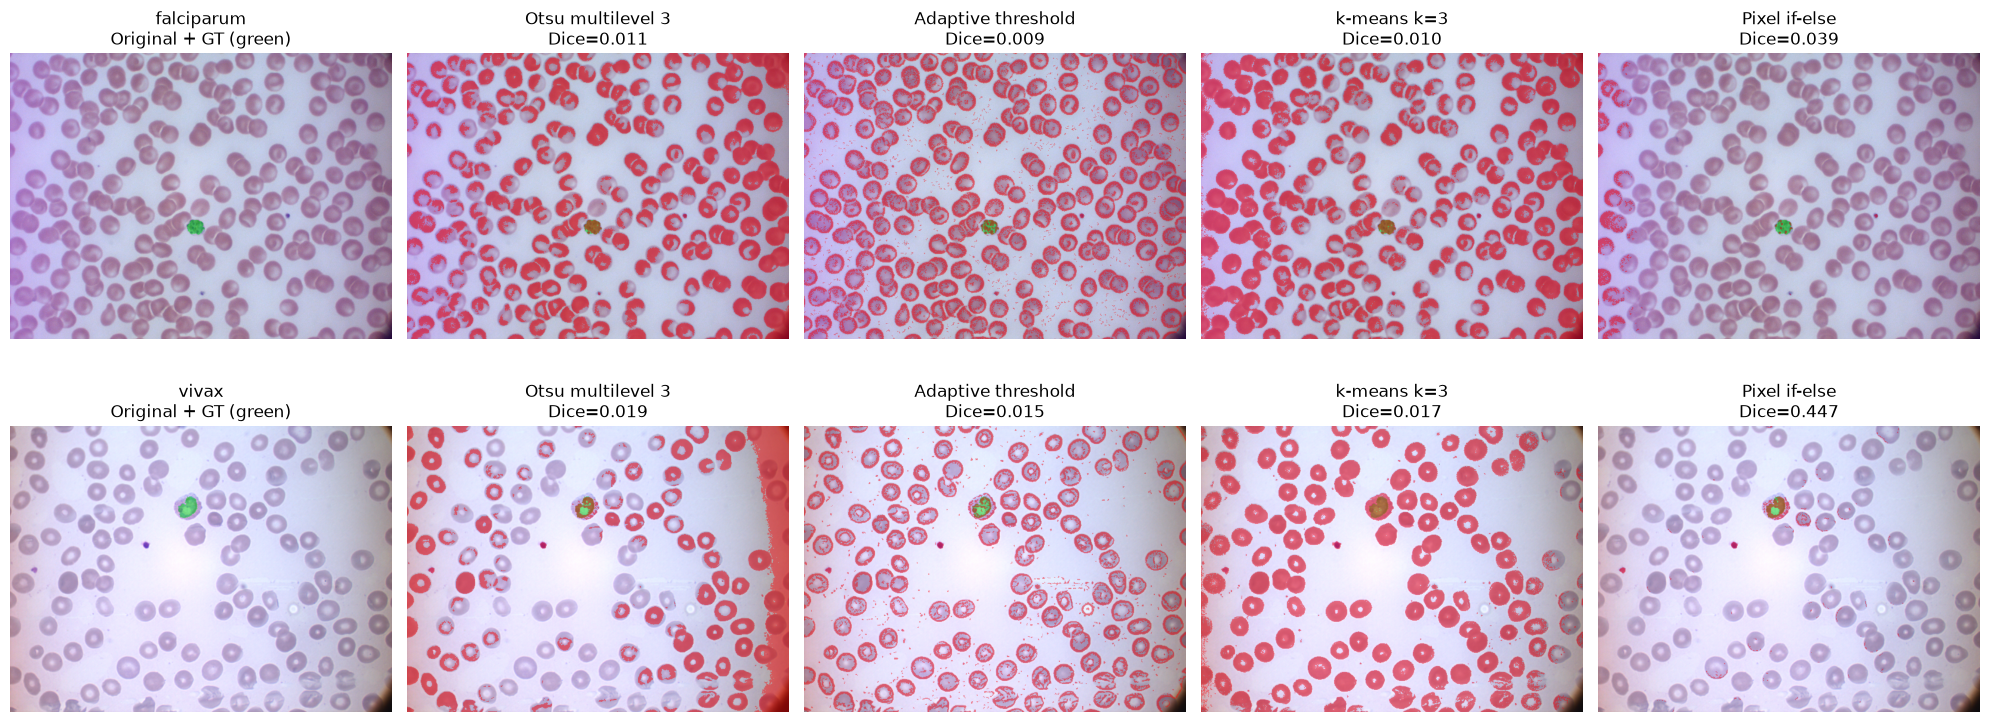

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for row_i, species in enumerate(['falciparum', 'vivax']):
    rec = next(r for r in TEST if r['species'] == species)
    axes[row_i, 0].imshow(overlay_small(rec['bgr'], rec['gt'], np.zeros_like(rec['gt'])))
    axes[row_i, 0].set_title(f"{species}\nOriginal + GT (green)")
    axes[row_i, 0].axis('off')
    for col_i, method in enumerate(['Otsu multilevel 3', 'Adaptive threshold', 'k-means k=3', 'Pixel if-else'], start=1):
        pred = a_masks[(rec['image_id'], method)]
        axes[row_i, col_i].imshow(overlay_small(rec['bgr'], rec['gt'], pred))
        d = pixel_metrics(pred, rec['gt'])['dice']
        axes[row_i, col_i].set_title(f"{method}\nDice={d:.3f}")
        axes[row_i, col_i].axis('off')
plt.tight_layout()
plt.show()

## 10. Eksperimen B — variasi preprocessing pada pixel-if-else

Varian yang dibandingkan:
- `B0_base`: L, P, S + median.
- `B1_clahe`: + CLAHE pada L.
- `B2_bg`: + background correction pada L.
- `B3_glcm`: + block GLCM (contrast/homogeneity/energy/correlation).
- `B4_lbp`: + LBP block entropy/uniformity dan local stats.
- `B5_texture`: + GLCM + LBP + local stats.
- `B6_combo`: CLAHE + background correction + GLCM + LBP.

Threshold pixel-if-else di-tuning ulang untuk setiap varian, tetap hanya pada train.
Varian terbaik dipilih berdasarkan **weighted train Dice**, bukan test.

In [14]:
variant_cfgs = [
    ('B0_base', {'variant': 'base', 'use_glcm': False, 'use_lbp': False}, False),
    ('B1_clahe', {'variant': 'clahe', 'use_glcm': False, 'use_lbp': False}, False),
    ('B2_bg', {'variant': 'bg', 'use_glcm': False, 'use_lbp': False}, False),
    ('B3_glcm', {'variant': 'glcm', 'use_glcm': True, 'use_lbp': False}, True),
    ('B4_lbp', {'variant': 'lbp', 'use_glcm': False, 'use_lbp': True}, True),
    ('B5_texture', {'variant': 'texture', 'use_glcm': True, 'use_lbp': True}, True),
    ('B6_combo', {'variant': 'combo', 'use_glcm': True, 'use_lbp': True}, True),
]

b_models = {}
b_rows = []

for name, cfg, use_texture in variant_cfgs:
    print(f'\n=== {name} ===')
    t0 = time.time()
    params, train_score = tune_pixel_ifelse(
        TRAIN,
        variant=cfg['variant'],
        use_glcm=cfg['use_glcm'],
        use_lbp=cfg['use_lbp'],
        use_texture=use_texture,
    )
    print('params:', params)
    print('weighted train Dice:', round(train_score, 4))

    test_metrics = []
    for rec in TEST:
        feat = feature_bundle(rec, cfg['variant'], cfg['use_glcm'], cfg['use_lbp'])
        pred = min_cleanup(pixel_mask_full(feat, params), 50)
        m = pixel_metrics(pred, rec['gt'])
        test_metrics.append(m)
        b_rows.append({
            'variant': name, 'species': rec['species'], 'image_id': rec['image_id'],
            **m,
        })
        del feat

    b_models[name] = {
        'cfg': cfg,
        'params': params,
        'train_score': float(train_score),
        'test_mean_dice': float(np.mean([m['dice'] for m in test_metrics])),
        'test_std_dice': float(np.std([m['dice'] for m in test_metrics], ddof=1)) if len(test_metrics) > 1 else 0.0,
        'test_mean_precision': float(np.mean([m['pixel_precision'] for m in test_metrics])),
        'test_mean_recall': float(np.mean([m['pixel_recall'] for m in test_metrics])),
        'elapsed': time.time() - t0,
    }
    print('mean test Dice:', round(b_models[name]['test_mean_dice'], 4),
          '| elapsed:', round(b_models[name]['elapsed'], 1), 's')

exp_b = pd.DataFrame(b_rows)
b_summary = pd.DataFrame([{
    'variant': k,
    'weighted_train_dice': v['train_score'],
    'test_mean_dice': v['test_mean_dice'],
    'test_std_dice': v['test_std_dice'],
    'test_mean_precision': v['test_mean_precision'],
    'test_mean_recall': v['test_mean_recall'],
    'params': v['params'],
    'elapsed_s': v['elapsed'],
} for k, v in b_models.items()]).set_index('variant')

print('\nRingkasan Eksperimen B:')
display(b_summary.sort_values('weighted_train_dice', ascending=False).round(4))

best_variant_name = max(b_models, key=lambda k: b_models[k]['train_score'])
best_cfg = b_models[best_variant_name]['cfg']
best_params = b_models[best_variant_name]['params']
print('Varian terbaik berdasarkan weighted train Dice:', best_variant_name)
print('Config:', best_cfg)
print('Params:', best_params)


=== B0_base ===


params: {'t_L': 0.5, 't_P': 0.95, 't_S': 0.9, 't_T': None, 't_core': 0.08, 'use_texture': False}
weighted train Dice: 0.2323


mean test Dice: 0.2263 | elapsed: 2.6 s

=== B1_clahe ===


params: {'t_L': 0.3, 't_P': 0.95, 't_S': 0.8, 't_T': None, 't_core': 0.08, 'use_texture': False}
weighted train Dice: 0.263


mean test Dice: 0.2734 | elapsed: 2.7 s

=== B2_bg ===


params: {'t_L': 0.6, 't_P': 0.95, 't_S': 0.9, 't_T': None, 't_core': 0.08, 'use_texture': False}
weighted train Dice: 0.2293


... (7 outputs left out)

params: {'t_L': 0.1, 't_P': 0.7, 't_S': 0.9, 't_T': 0.8, 't_core': 0.08, 'use_texture': True}
weighted train Dice: 0.18


mean test Dice: 0.333 | elapsed: 5.5 s

Ringkasan Eksperimen B:


,weighted_train_dice,test_mean_dice,test_std_dice,test_mean_precision,test_mean_recall,params,elapsed_s
variant,,,,,,,
B3_glcm,0.2632,0.3194,0.1632,0.2709,0.4531,"{'t_L': 0.5, 't_P': 0.7, 't_S': 0.9, 't_T': 0....",4.4996
B1_clahe,0.2630,0.2734,0.2892,0.2375,0.3604,"{'t_L': 0.3, 't_P': 0.95, 't_S': 0.8, 't_T': N...",2.6535
B0_base,0.2323,0.2263,0.2381,0.1637,0.3974,"{'t_L': 0.5, 't_P': 0.95, 't_S': 0.9, 't_T': N...",2.5738
B2_bg,0.2293,0.1982,0.2059,0.1331,0.4124,"{'t_L': 0.6, 't_P': 0.95, 't_S': 0.9, 't_T': N...",2.7900
B5_texture,0.2004,0.2077,0.1816,0.1518,0.3332,"{'t_L': 0.5, 't_P': 0.95, 't_S': 0.8, 't_T': 0...",5.2660
B6_combo,0.1800,0.3330,0.1981,0.3592,0.3294,"{'t_L': 0.1, 't_P': 0.7, 't_S': 0.9, 't_T': 0....",5.5430
B4_lbp,0.1398,0.1978,0.1650,0.3697,0.1499,"{'t_L': 0.1, 't_P': 0.7, 't_S': 0.9, 't_T': 0....",3.7137


Varian terbaik berdasarkan weighted train Dice: B3_glcm
Config: {'variant': 'glcm', 'use_glcm': True, 'use_lbp': False}
Params: {'t_L': 0.5, 't_P': 0.7, 't_S': 0.9, 't_T': 0.65, 't_core': 0.08, 'use_texture': True}


## 11. Object-level if-else pada output pixel-if-else

Aturan object-level diturunkan dari fitur objek GT pada **train**:
- area min/max,
- rata-rata L, purple score, saturation,
- solidity,
- border,
- (untuk C3) GLCM entropy dan LBP entropy.

Aturan kemudian diterapkan pada connected components dari output pixel-if-else yang sudah dimorphology.
Tidak ada threshold yang diambil dari test.

In [15]:
object_rules, gt_feature_table = derive_object_rules(TRAIN, best_cfg)
print('Object-level rules dari train:')
for k, v in object_rules.items():
    print(f'  {k}: {v}')

print('\nFitur objek GT pada train:')
display(gt_feature_table[['label', 'area', 'mean_L', 'mean_P', 'mean_S',
                           'solidity', 'glcm_entropy', 'lbp_entropy',
                           'local_contrast', 'touches_border']].round(3))

Object-level rules dari train:
  area_min: 2301.25
  area_max: 38866.0
  L_max: 193.50377456722634
  P_min: 33.92080307006836
  S_min: 61.76828075953276
  solidity_min: 0.6879632655729132
  entropy_min: 5.521307909422684
  lbp_entropy_min: 1.9864117622375488
  reject_border: True

Fitur objek GT pada train:


,label,area,mean_L,mean_P,mean_S,solidity,glcm_entropy,lbp_entropy,local_contrast,touches_border
0,1,6575.0,125.325,54.279,103.062,0.843,6.135,2.490,77.207,False
1,1,12820.0,143.420,45.159,89.533,0.838,5.922,2.286,71.476,False
2,1,15366.0,173.504,51.835,76.793,0.883,6.346,2.520,44.014,False
3,1,19433.0,141.988,43.921,76.768,0.926,5.821,2.531,46.671,False


In [16]:
c_rows = []
c_masks = {}

for rec in TEST:
    feat = feature_bundle(rec, best_cfg['variant'], best_cfg['use_glcm'], best_cfg['use_lbp'])
    raw = pixel_mask_full(feat, best_params)
    morph = merge_fragments(raw, close_k=15, min_area=300)

    lab_img = label(morph, connectivity=2)
    if lab_img.max() > 0:
        feats = pd.DataFrame(component_features(
            lab_img, feat['L'], feat['P'], feat['S'],
            min_area=max(50, int(object_rules['area_min'] * 0.5)),
            with_texture=True,
        ))
    else:
        feats = pd.DataFrame()

    c2 = filter_from_features(lab_img, feats, object_rules, use_texture=False)
    c3 = filter_from_features(lab_img, feats, object_rules, use_texture=True)

    modes = {
        'C0_raw': raw,
        'C1_morphology': morph,
        'C2_object': c2,
        'C3_object_texture': c3,
    }
    for mode, pred in modes.items():
        pm = pixel_metrics(pred, rec['gt'])
        om = object_metrics(pred, rec['gt_labels'])
        c_rows.append({
            'species': rec['species'], 'image_id': rec['image_id'], 'mode': mode,
            **pm, **om,
        })
        c_masks[(rec['image_id'], mode)] = pred
    del feat

exp_c = pd.DataFrame(c_rows)
display(exp_c[['species', 'image_id', 'mode', 'dice', 'iou', 'pixel_precision',
               'pixel_recall', 'obj_recall', 'obj_precision', 'n_gt', 'n_pred', 'obj_fp']].round(4))

c_summary = (exp_c.groupby('mode')
             .agg(mean_dice=('dice', 'mean'),
                  median_dice=('dice', 'median'),
                  std_dice=('dice', 'std'),
                  mean_iou=('iou', 'mean'),
                  mean_pixel_precision=('pixel_precision', 'mean'),
                  mean_pixel_recall=('pixel_recall', 'mean'),
                  mean_obj_recall=('obj_recall', 'mean'),
                  mean_obj_precision=('obj_precision', 'mean'),
                  total_gt=('n_gt', 'sum'),
                  total_pred=('n_pred', 'sum'),
                  total_fp=('obj_fp', 'sum'),
                  mean_fp_per_image=('obj_fp', 'mean'))
             .sort_values('mean_dice', ascending=False))
print('\nRingkasan Eksperimen C (test):')
display(c_summary.round(4))

,species,image_id,mode,dice,iou,pixel_precision,pixel_recall,obj_recall,obj_precision,n_gt,n_pred,obj_fp
0,falciparum,1305121398-0010-S.jpg,C0_raw,0.3846,0.2381,0.3814,0.3879,1.0,0.0041,1,245,244
1,falciparum,1305121398-0010-S.jpg,C1_morphology,0.7052,0.5446,0.6450,0.7777,1.0,0.1429,1,7,6
2,falciparum,1305121398-0010-S.jpg,C2_object,0.8721,0.7732,0.9926,0.7777,1.0,1.0000,1,1,0
3,falciparum,1305121398-0010-S.jpg,C3_object_texture,0.8721,0.7732,0.9926,0.7777,1.0,1.0000,1,1,0
4,falciparum,1305121398-0022-S.jpg,C0_raw,0.0880,0.0460,0.0623,0.1499,0.0,0.0000,1,100,100
5,falciparum,1305121398-0022-S.jpg,C1_morphology,0.1088,0.0575,0.0757,0.1935,1.0,0.0833,1,12,11
6,falciparum,1305121398-0022-S.jpg,C2_object,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,1,0,0
7,falciparum,1305121398-0022-S.jpg,C3_object_texture,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,1,0,0
8,vivax,1709041080-0038-S.jpg,C0_raw,0.3706,0.2274,0.2463,0.7484,1.0,0.0012,1,800,799
9,vivax,1709041080-0038-S.jpg,C1_morphology,0.4780,0.3140,0.3147,0.9931,1.0,0.0417,1,24,23



Ringkasan Eksperimen C (test):


,mean_dice,median_dice,std_dice,mean_iou,mean_pixel_precision,mean_pixel_recall,mean_obj_recall,mean_obj_precision,total_gt,total_pred,total_fp,mean_fp_per_image
mode,,,,,,,,,,,,
C3_object_texture,0.6479,0.8178,0.4391,0.5766,0.6495,0.6748,0.75,0.7500,4,3,0,0.00
C2_object,0.6479,0.8178,0.4391,0.5766,0.6495,0.6748,0.75,0.7500,4,3,0,0.00
C1_morphology,0.4613,0.5157,0.2533,0.3247,0.3574,0.7231,1.00,0.0729,4,85,81,20.25
C0_raw,0.2884,0.3405,0.1374,0.1738,0.2264,0.4598,0.75,0.0016,4,1935,1932,483.00


## 12. Visualisasi perbandingan pipeline

Overlay: GT = hijau, prediksi = merah. Area yang tumpang-tindih menjadi campuran kuning/coklat.
Visualisasi memakai downscale hanya untuk tampilan; evaluasi tetap pada resolusi penuh.

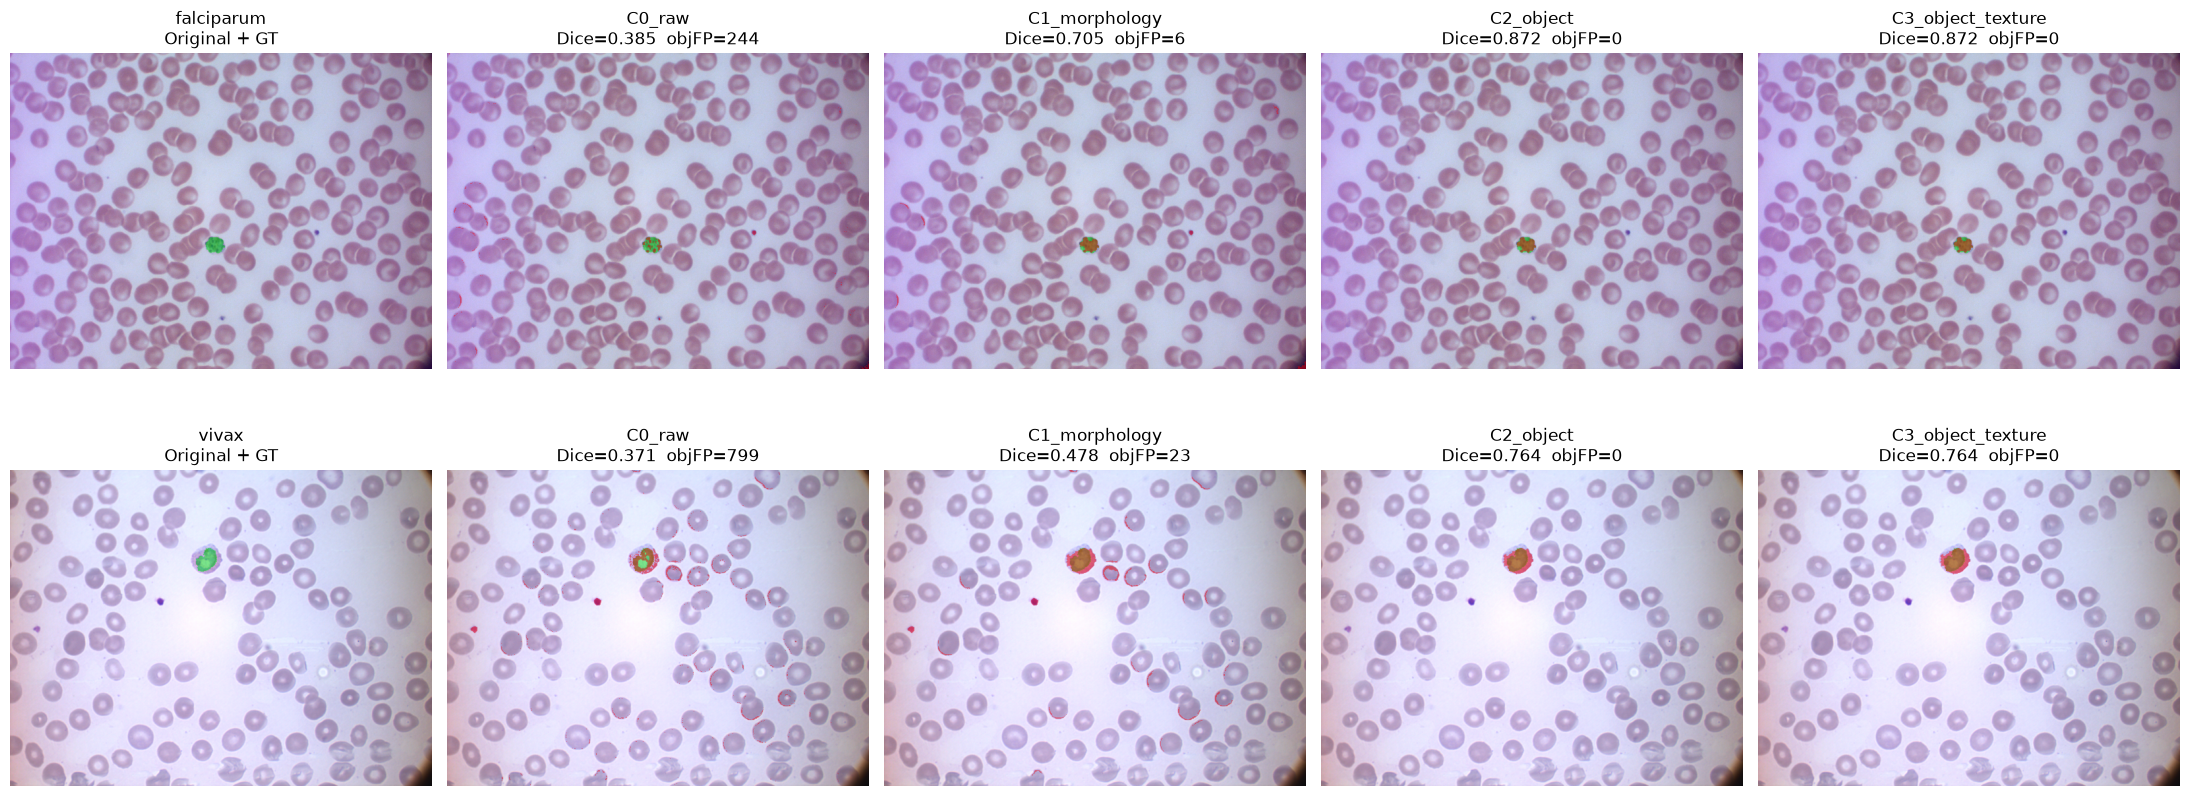

Saved: /home/opencode/workspace/results/experiment_c_examples.png


In [17]:
mode_order = ['C0_raw', 'C1_morphology', 'C2_object', 'C3_object_texture']
fig, axes = plt.subplots(2, 5, figsize=(22, 9))

for row_i, species in enumerate(['falciparum', 'vivax']):
    rec = next(r for r in TEST if r['species'] == species)
    axes[row_i, 0].imshow(overlay_small(rec['bgr'], rec['gt'], np.zeros_like(rec['gt'])))
    axes[row_i, 0].set_title(f"{species}\nOriginal + GT")
    axes[row_i, 0].axis('off')

    for col_i, mode in enumerate(mode_order, start=1):
        pred = c_masks[(rec['image_id'], mode)]
        axes[row_i, col_i].imshow(overlay_small(rec['bgr'], rec['gt'], pred))
        d = pixel_metrics(pred, rec['gt'])['dice']
        om = object_metrics(pred, rec['gt_labels'])
        axes[row_i, col_i].set_title(f"{mode}\nDice={d:.3f}  objFP={om['obj_fp']}")
        axes[row_i, col_i].axis('off')

plt.tight_layout()
fig_path = RESULTS_DIR / 'experiment_c_examples.png'
plt.savefig(fig_path, dpi=110, bbox_inches='tight')
plt.show()
print('Saved:', fig_path)

## 13. Failure case dan ringkasan

Kita tampilkan citra test dengan Dice terendah pada C3, pada crop di sekitar GT.
Ini penting karena rata-rata saja dapat menyembunyikan kegagalan pada satu citra.

Worst C3 case: 1305121398-0022-S.jpg | Dice = 0.0


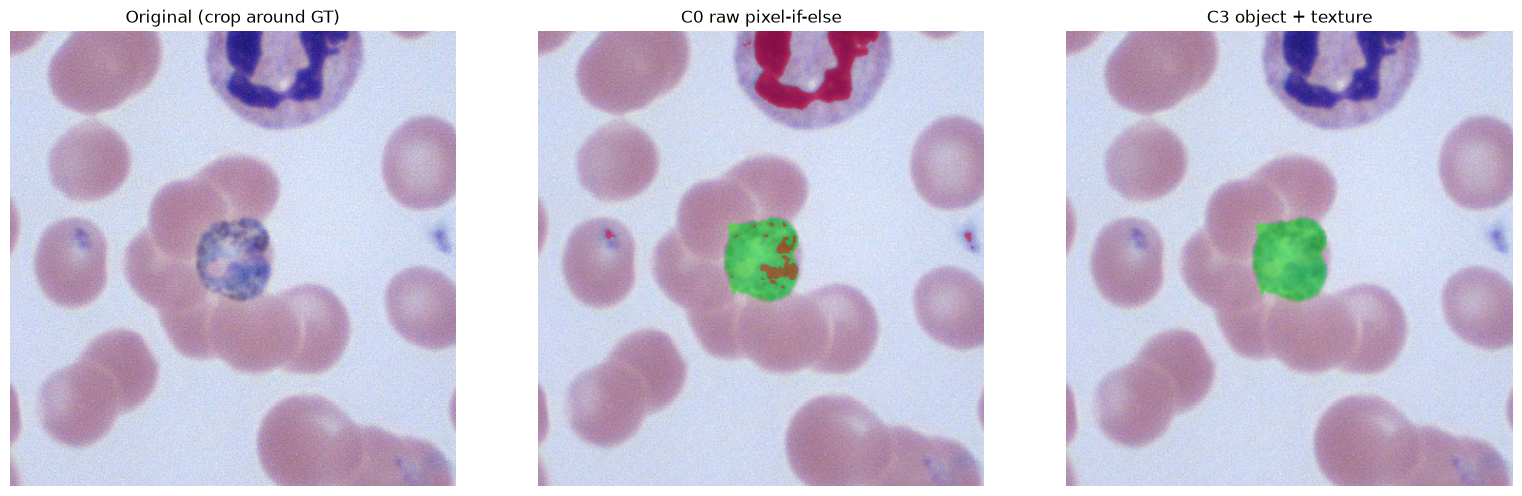

Saved: /home/opencode/workspace/results/failure_case.png


In [18]:
worst_row = (exp_c[exp_c['mode'] == 'C3_object_texture']
             .sort_values('dice').iloc[0])
worst_rec = next(r for r in TEST if r['image_id'] == worst_row['image_id'])
print('Worst C3 case:', worst_row['image_id'], '| Dice =', round(worst_row['dice'], 4))

ys, xs = np.where(worst_rec['gt'] > 0)
pad = 260
y0, y1 = max(0, ys.min() - pad), min(worst_rec['shape'][0], ys.max() + pad)
x0, x1 = max(0, xs.min() - pad), min(worst_rec['shape'][1], xs.max() + pad)

def crop_img(x):
    return x[y0:y1, x0:x1]

gt_crop = crop_img(worst_rec['gt'])
c0_crop = crop_img(c_masks[(worst_rec['image_id'], 'C0_raw')])
c3_crop = crop_img(c_masks[(worst_rec['image_id'], 'C3_object_texture')])
rgb_crop = cv2.cvtColor(crop_img(worst_rec['bgr']), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (img, title, cmap) in zip(axes, [
    (rgb_crop, 'Original (crop around GT)', None),
    (overlay_small(crop_img(worst_rec['bgr']), gt_crop, c0_crop, width=520), 'C0 raw pixel-if-else', None),
    (overlay_small(crop_img(worst_rec['bgr']), gt_crop, c3_crop, width=520), 'C3 object + texture', None),
]):
    ax.imshow(img, cmap=cmap)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
fig_path = RESULTS_DIR / 'failure_case.png'
plt.savefig(fig_path, dpi=110, bbox_inches='tight')
plt.show()
print('Saved:', fig_path)

## 14. Menyimpan hasil dan kesimpulan

Semua tabel disimpan ke `results/` agar dapat diperiksa tanpa menjalankan ulang notebook.

In [19]:
selected[['image_id', 'species', 'split', 'n_objects', 'areas', 'total_area']].to_csv(
    RESULTS_DIR / 'selected_images.csv', index=False
)
channel_selection.to_csv(RESULTS_DIR / 'channel_selection.csv', index=False)
exp_a.to_csv(RESULTS_DIR / 'experiment_a.csv', index=False)
exp_b.to_csv(RESULTS_DIR / 'experiment_b.csv', index=False)
exp_c.to_csv(RESULTS_DIR / 'experiment_c.csv', index=False)

with open(RESULTS_DIR / 'best_model.json', 'w') as f:
    json.dump({
        'selected_channel_for_threshold': SELECTED_CHANNEL,
        'best_variant': best_variant_name,
        'best_cfg': best_cfg,
        'best_params': best_params,
        'object_rules': object_rules,
        'base_params': base_params,
    }, f, indent=2, default=str)

print('Saved files:')
for p in sorted(RESULTS_DIR.glob('*')):
    print(' -', p.name)

print('\n=== ANGKA KUNCI ===')
print('Base pixel-if-else weighted train Dice:', round(base_train_score, 4))
print('Best preprocessing variant:', best_variant_name)
print('Best weighted train Dice:', round(b_models[best_variant_name]['train_score'], 4))
print('\nEksperimen A (mean test Dice):')
print(exp_a_summary['mean_dice'].round(4).to_string())
print('\nEksperimen B (mean test Dice):')
print(b_summary['test_mean_dice'].round(4).sort_values(ascending=False).to_string())
print('\nEksperimen C (mean test Dice):')
print(c_summary['mean_dice'].round(4).to_string())

Saved files:
 - best_model.json
 - channel_selection.csv
 - experiment_a.csv
 - experiment_b.csv
 - experiment_c.csv
 - experiment_c_examples.png
 - failure_case.png
 - selected_images.csv

=== ANGKA KUNCI ===
Base pixel-if-else weighted train Dice: 0.2323
Best preprocessing variant: B3_glcm
Best weighted train Dice: 0.2632

Eksperimen A (mean test Dice):
method
Pixel if-else         0.2263
k-means k=3           0.0170
Otsu multilevel 3     0.0168
Adaptive threshold    0.0139

Eksperimen B (mean test Dice):
variant
B6_combo      0.3330
B3_glcm       0.3194
B1_clahe      0.2734
B0_base       0.2263
B5_texture    0.2077
B2_bg         0.1982
B4_lbp        0.1978

Eksperimen C (mean test Dice):
mode
C3_object_texture    0.6479
C2_object            0.6479
C1_morphology        0.4613
C0_raw               0.2884


## 15. Kesimpulan dan keterbatasan

### Temuan yang perlu dibaca bersama tabel

1. **Preprocessing minimal belum cukup untuk falciparum.**  
   RBC, tepi citra, dan artefak kompresi JPG juga gelap/ungu. Threshold warna global karenanya menghasilkan banyak false positive. Vivax relatif lebih mudah karena kontras warna parasite terhadap RBC lebih besar.

2. **Pixel-if-else standalone menghasilkan recall yang lebih baik daripada precision.**  
   Fragmen parasite sering tertangkap, tetapi banyak komponen lain juga ikut. Object-level if-else dapat membuang komponen yang jelas tidak masuk akal (area terlalu kecil/besar, border, solidity rendah), tetapi tidak dapat mengembalikan piksel parasite yang sejak awal tidak lolos threshold.

3. **Morphology membantu menyatukan fragmen.**  
   Closing elips 15x15 dan filling hole kecil menggabungkan fragmen parasite. Namun kernel terlalu besar juga menggabungkan false positive di sekitarnya, sehingga object-level filtering tetap diperlukan.

4. **Block GLCM/LBP bukan solusi otomatis.**  
   Tekstur dihitung pada blok 32x32; parasite schizont kecil sehingga banyak blok didominasi RBC/background. Feature map juga terkena artefak JPG. Varian terbaik pada train belum tentu terbaik pada test karena hanya 4 citra train.

5. **Hasil ini eksploratif.**  
   Dengan 8 citra (4 train, 4 test) dan 1–2 objek per citra, angka Dice/objek sangat sensitif terhadap satu kasus. Jangan menyimpulkan generalisasi ke seluruh MP-IDB dari tabel ini.

### Hasil eksekusi ini (test)

- **Pemilihan kanal.** Pada train, `L` memberi mean Dice tertinggi untuk Otsu/adaptive (0.0121), jauh di atas `S` (0.0024) dan `P` (0.0018). Effect size lokal `S`/`P` besar, tetapi threshold global pada kanal tersebut menangkap area saturasi/ungu yang luas. Karena itu `L` dipakai untuk Otsu/adaptive.
- **Eksperimen A.** Pixel-if-else memberi mean Dice 0.226; Otsu multilevel 0.017, k-means 0.017, adaptive 0.014. Metode global punya recall tinggi (0.58–0.87) tetapi precision sangat rendah (sekitar 0.007–0.009), artinya mask mencakup area yang jauh lebih besar daripada parasit.
- **Eksperimen B.** Berdasarkan weighted train Dice, `B3_glcm` terpilih. Pada test, `B6_combo` sedikit lebih tinggi (0.333 vs 0.319), tetapi `B6` tidak dipilih karena skor train-nya lebih rendah. Ini contoh variansi train/test dengan hanya 4 citra train.
- **Eksperimen C.** C2/C3 memberi mean Dice 0.648, dibanding C1 0.461 dan C0 0.288. Object-level menaikkan precision objek dari 0.073 (C1) menjadi 0.75, tetapi pada satu citra falciparum (`1305121398-0022-S.jpg`) semua komponen dibuang sehingga Dice menjadi 0. Citra ini adalah failure case.
- **C3 vs C2.** Aturan tekstur tidak mengubah keputusan pada empat citra test; C3 identik dengan C2. Ini bukan bukti tekstur tidak berguna, hanya belum cukup diskriminatif pada sampel kecil ini.

### Keterbatasan teknis

- Stage pada anotasi bersifat image-level; semua objek pada citra ber-tag `schizont` diperlakukan sebagai schizont.
- Tidak ada resizing, sehingga parameter morphology/tekstur berada pada skala piksel penuh.
- GT dapat mencakup seluruh badan schizont, termasuk bagian yang tidak terlalu gelap; threshold warna hanya menangkap bagian inti.
- Background correction dan CLAHE bersifat global/per-image, bukan stain normalization antar-citra.
- Object-level rules diturunkan dari hanya 4 objek GT train (falciparum 2, vivax 2), sehingga rentang area/warna sangat lebar.
- Evaluasi objek memakai IoU ≥10%; ambang ini cukup toleran, tetapi tetap menghukum prediksi yang terfragmentasi.

### Rekomendasi lanjutan

- Tambah citra train/test dan lakukan validasi silang per spesies.
- Coba segmentasi berbasis **region growing / hysteresis threshold** dari seed ber-confidence tinggi.
- Gunakan **stain normalization** atau color deconvolution sebelum threshold.
- Untuk object-level, tambahkan fitur bentuk yang lebih stabil (mis. rasio area terhadap convex hull, jumlah internal nuclei) dan tuning terpisah per spesies.
- Laporkan kurva precision-recall, bukan hanya satu titik threshold.
- Simpan parameter dan cache fitur agar eksperimen dapat direproduksi.